# SmishGuard Model Training and Evaluation

## A. Research objective and environment
Compare standard Multinomial NB, Logistic Regression and Linear SVM before testing the user-supplied BantayText hypothesis. Positive class: **smishing=1**, ham=0. Offline Philippine financial SMS detection is the intended use; the available corpus includes broader phishing. All labels are inherited source/rule labels, with independent review pending. These are retrospective experiments, even after a new grouped split. No dataset, SMS examples, fitted vocabulary, credentials or model parameters are embedded in this notebook.

In [1]:
# Colab/Jupyter installation, when needed. Run once in a fresh environment.
# %pip install numpy==2.2.6 scipy==1.15.3 scikit-learn==1.6.1 joblib==1.6.0 pandas==2.3.3 matplotlib==3.10.7
import platform, sys, os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
print("Python",platform.python_version())
# Run from repository research/, or upload the authorized masked dataset.json to Colab.
# Colab: from google.colab import files; files.upload()  # authorized file only
DATASET=Path(os.environ.get("SMISHGUARD_DATASET", "data/newdata-20261013/experiment-v2/dataset.json"))
if not DATASET.exists():
    DATASET=Path("dataset.json")
assert DATASET.exists(), "Supply authorized masked dataset.json; see reproduction guide"
RUN=Path(os.environ.get("SMISHGUARD_RUN", "runs/bantaytext-20261013/notebook-run"))
assert not RUN.exists(), "Use a new run directory to preserve frozen results"

Python 3.12.5


In [2]:
"""Baseline-first retrospective research; never installs a model or changes app policy.

The notebook embeds these functions so its training/metric code is visible and runnable.
Populated ledgers, vocabulary and fitted parameters belong only in ignored storage.
"""
from collections import Counter, defaultdict
from difflib import SequenceMatcher
from pathlib import Path
import argparse
import csv
import hashlib
import importlib.metadata
import json
import pickle
import re
import time

import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, roc_auc_score, brier_score_loss, log_loss)

SEED = 42
URL = re.compile(r'https?://\S+|www\.\S+', re.I)
PLACEHOLDER = re.compile(r'<(?:REAL NAME|NAME|REDACTED|BLANK|n)>|\[name redacted\]|\(full name\)|\[my name\]', re.I)


def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')


def load(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def class_counts(rows):
    labels = Counter(int(r['label']) for r in rows)
    return dict(records=len(rows), ham=labels[0], smishing=labels[1],
                scam_fraction=labels[1]/len(rows) if rows else None)


def clean_rows(records):
    """Source labels stay intact; flagged/unsupported/conflicting rows are held.

    Input is the existing source-joined, identifier-masked fitting view. We do not
    automatically grant permission to raw sources or run the supplied rule builder.
    """
    staged, ledger = [], []
    for i, r in enumerate(records):
        raw = r.get('text')
        text = re.sub(r'\s+', ' ', PLACEHOLDER.sub(' ', raw)).strip(' ,') if isinstance(raw, str) else ''
        label = r.get('label')
        reason = ('empty' if not text else 'unsupported_label' if type(label) is not int or label not in (0, 1)
                  else 'pending_flagged_review' if str(r.get('needs_review', '')).lower() == 'true' else None)
        key = text.lower()
        staged.append(dict(r, text=text, _key=key, _row=i))
        ledger.append(dict(row=i, id=r.get('id'), original_label=label,
            original_text_sha256=hashlib.sha256((raw or '').encode()).hexdigest(),
            text_changed=raw != text, reason=reason))
    buckets = defaultdict(list)
    for r in staged:
        # Conflicts include flagged records: do not retain the other side as certainty.
        if r['text'] and type(r.get('label')) is int and r['label'] in (0, 1):
            buckets[r['_key']].append(r)
    conflict_keys = {key for key, rr in buckets.items() if len({r['label'] for r in rr}) > 1}
    seen, retained = set(), []
    for r in staged:
        entry = ledger[r['_row']]
        if r['_key'] in conflict_keys:
            entry['reason'] = 'conflicting_exact_labels'
        if not entry['reason']:
            if r['_key'] in seen:
                entry['reason'] = 'duplicate_masked_casefold_text'
            else:
                seen.add(r['_key'])
                retained.append({k:v for k,v in r.items() if not k.startswith('_')})
    return retained, ledger, dict(before=class_counts([r for r in records if type(r.get('label')) is int and r['label'] in (0,1)]),
        after=class_counts(retained), removals=dict(Counter(e['reason'] for e in ledger if e['reason'])),
        conflicting_exact_groups=len(conflict_keys), missing_fields={k:sum(not r.get(k) for r in records) for k in ('text','source','category','language')},
        input_labels={str(k):v for k,v in Counter(r.get('label') for r in records).items()},
        transformations='Remove known placeholder spans, collapse whitespace, hold flagged/unsupported/conflicting records, retain first masked casefold duplicate',
        label_mapping={'0':'ham', '1':'smishing'}, label_status='Inherited source/rule labels; independently unverified')



In [3]:
np.random.seed(SEED)
print("Seed",SEED)
print({k:importlib.metadata.version(k) for k in ("numpy","scipy","scikit-learn","pandas","matplotlib")})

Seed 42
{'numpy': '2.2.6', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'pandas': '2.3.3', 'matplotlib': '3.10.7'}


## B. Dataset loading and inspection
Required JSON: list of records with `id`, masked `text`, binary integer `label`, `source`, `category`, `language`; `needs_review` and `template_group` are retained where available. This default uses the existing source-joined and automatically masked 3,340-record fitting view, not the raw 4,261-record package. The raw package/source audits remain separate. Never concatenate auxiliary copies, admit held sources, or map `gambling_ad` to ham automatically. Display aggregate counts only.

Dimensions (3340, 10) Columns ['id', 'text', 'text_redacted', 'label', 'template_group', 'source', 'language', 'category', 'needs_review', 'content_sha256']


id                0
text              0
text_redacted     0
label             0
template_group    0
source            0
language          0
category          0
needs_review      0
content_sha256    0
Name: missing, dtype: int64

label
0    2947
1     393
Name: original label counts, dtype: int64

Whitespace-only 0
Exact duplicates 725


label,0,1
source,,
bwandowando,17,163
marketing,877,164
tagalog,2053,66


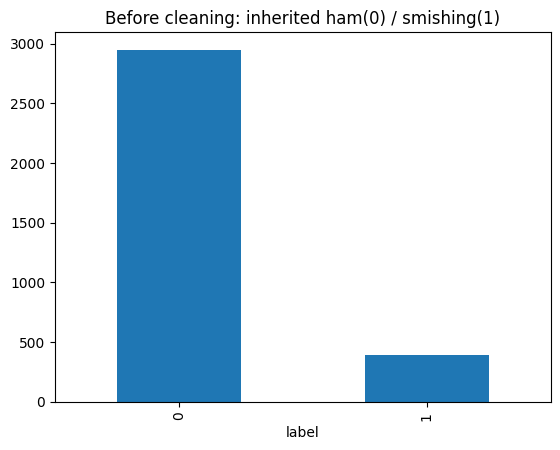

In [4]:
raw=load(DATASET)
frame=pd.DataFrame(raw)
print("Dimensions",frame.shape,"Columns",list(frame.columns))
display(frame.isna().sum().rename("missing"))
display(frame["label"].value_counts(dropna=False).rename("original label counts"))
print("Whitespace-only",sum(not str(x or "").strip() for x in frame["text"]))
print("Exact duplicates",frame["text"].duplicated().sum())
display(pd.crosstab(frame["source"],frame["label"]))
frame["label"].value_counts().sort_index().plot.bar(title="Before cleaning: inherited ham(0) / smishing(1)")
plt.show()

## C. Cleaning and label preparation
The function above removes known dataset placeholders, collapses whitespace, holds flagged or unsupported labels, holds exact conflicting labels (including conflicts with flagged rows), and keeps the first masked casefold duplicate. No Filipino stopwords are removed. Original labels/source remain in a private row ledger. Upstream masking cannot be reversed: raw URL host performance cannot be measured here. Human review is unavailable, so retained records are computationally usable rather than independently confirmed truth.

In [5]:

def template_key(text):
    # Label-blind grouping uses a broader normalization than the training features.
    text = URL.sub(' ', text.lower())
    text = re.sub(r'\bzz(?:url|number|email)zz\b|[0-9]+', ' ', text)
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z]+', ' ', text)).strip()


def make_groups(rows):
    texts = [template_key(r['text']) for r in rows]
    counts = [Counter(t) for t in texts]
    parent = list(range(len(rows)))
    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i in range(len(rows)):
        for j in range(i):
            if root(i) == root(j):
                continue
            supplied_equal = bool(rows[i].get('template_group')) and rows[i].get('template_group') == rows[j].get('template_group')
            if texts[i] == texts[j] or supplied_equal:
                parent[root(i)] = root(j)
                continue
            total = len(texts[i])+len(texts[j])
            if 2*min(len(texts[i]),len(texts[j]))/max(1,total) < .85:
                continue
            bound = 2*sum(min(v,counts[j].get(c,0)) for c,v in counts[i].items())/max(1,total)
            if bound >= .85 and SequenceMatcher(None,texts[i],texts[j],autojunk=False).ratio() >= .85:
                parent[root(i)] = root(j)
    return np.array([root(i) for i in range(len(rows))])


def partitions(rows, groups, track):
    y = np.array([r['label'] for r in rows]); ids = np.arange(len(rows))
    if track == 'random':
        train, held = train_test_split(ids,test_size=.4,stratify=y,random_state=SEED)
        val, test = train_test_split(held,test_size=.5,stratify=y[held],random_state=SEED)
    elif track == 'grouped':
        folds = [b for _,b in StratifiedGroupKFold(n_splits=10,shuffle=True,random_state=SEED).split(ids,y,groups)]
        train, val, test = (np.concatenate(folds[a:b]) for a,b in ((0,6),(6,8),(8,10)))
    else:
        raise ValueError('Unknown track')
    result = dict(train=train.tolist(), validation=val.tolist(), test=test.tolist())
    if any(len(set(y[ii])) != 2 for ii in result.values()):
        raise ValueError('Both classes required in each partition; no favorable-seed retry')
    assert len(set(train)|set(val)|set(test)) == len(rows)
    overlap = {a+'-'+b:len(set(groups[result[a]])&set(groups[result[b]])) for a in result for b in result if a<b}
    if track == 'grouped':
        assert not any(overlap.values())
    return result, dict(support={p:class_counts([rows[i] for i in ii]) for p,ii in result.items()},
        template_overlap=overlap, strategy='two-step stratified 60/20/20' if track=='random' else '10 stratified group folds allocated 6/2/2; approximate 60/20/20',
        seed=SEED, temporal='Unavailable: collection dates lack verified receipt-time meaning and timezone')



## D. Splitting and leakage prevention
Random: two-step stratified 60/20/20, seed 42, natural class ratio. Grouped: label-blind connected components from supplied templates and normalized SequenceMatcher similarity ≥0.85; 10 stratified group folds assigned 6/2/2. Approximate proportions can differ. Near similarity is a heuristic; it cannot prove campaign independence. The complete configuration and splits are saved before fitting. Dates lack verified receipt meaning/timezone: temporal evaluation is unavailable.

In [6]:

def experiment_matrix():
    base = [dict(id=f'baseline-{a}',phase='baseline',algorithm=a,features='word',ngrams=[1,1],stop_words=None,
                 alpha=1.0,C=1.0,class_weight=None,calibrated=False,tune_threshold=False) for a in ('nb','lr','svm')]
    experiments = list(base)
    for a in ('nb','lr','svm'):
        ref = dict(phase='improvement',algorithm=a,features='word',ngrams=[1,2],stop_words='english',
            alpha=.1,C=1.0,class_weight=None,calibrated=a=='svm',tune_threshold=True)
        experiments.append(dict(ref,id=f'{a}-word12-english'))
        experiments.append(dict(ref,id=f'{a}-word12-no-stop',stop_words=None))
        for feature in ('char','combined'):
            experiments.append(dict(ref,id=f'{a}-{feature}',features=feature))
        if a=='nb':
            for alpha in (.03,.3,1.0):
                experiments.append(dict(ref,id=f'nb-alpha-{alpha}',alpha=alpha))
            experiments.append(dict(ref,id='nb-word1-english',ngrams=[1,1]))
        else:
            for c in (.1,10.0):
                experiments.append(dict(ref,id=f'{a}-C-{c}',C=c))
            experiments.append(dict(ref,id=f'{a}-balanced',class_weight='balanced'))
        if a=='lr':
            experiments.append(dict(ref,id='lr-oof-calibrated',calibrated=True))
        if a=='svm':
            experiments.append(dict(ref,id='svm-word1-calibrated',ngrams=[1,1],stop_words=None))
    experiments.append(dict(phase='improvement',id='lr-portable',algorithm='lr',features='portable',ngrams=[1,1],
        stop_words=None,C=1.0,class_weight=None,calibrated=True,tune_threshold=True))
    # Prespecified shortcut diagnostics, excluded from winner selection.
    for ablation in ('remove_urls','placeholders_only','source_only'):
        experiments.append(dict(phase='diagnostic',id='lr-'+ablation,algorithm='lr',features='word',ngrams=[1,2],
            stop_words='english',C=1.0,class_weight=None,calibrated=False,tune_threshold=True,ablation=ablation))
    return experiments


def prepare_run(dataset, output):
    if output.exists():
        raise ValueError('Use a fresh run directory; never overwrite a frozen experiment')
    output.mkdir(parents=True)
    raw = load(dataset)
    rows,ledger,audit = clean_rows(raw)
    save(output/'cleaning-ledger.json',ledger); save(output/'dataset.json',rows)
    groups = make_groups(rows)
    audit.update(template_groups=len(set(groups)), mixed_label_template_groups=sum(len({rows[i]['label'] for i in np.flatnonzero(groups==g)})>1 for g in set(groups)),
        grouping='Label-blind supplied templates + ASCII URL/identifier-stripped SequenceMatcher >=.85 connected components; heuristic, not verified campaign identity',
        sources={s:class_counts([r for r in rows if r['source']==s]) for s in sorted({r['source'] for r in rows})},
        human_review='Pending; no category converted to ground truth',data_history='Previously exposed; retrospective comparisons only')
    save(output/'data-audit.json',audit)
    manifests = {}; support = {}
    for track in ('random','grouped'):
        manifests[track],support[track] = partitions(rows,groups,track)
    save(output/'splits.json',dict(groups=groups.tolist(),partitions=manifests,support=support))
    cfg = dict(seed=SEED,input_sha256=digest(dataset),cleaned_sha256=digest(output/'dataset.json'),
        split_sha256=digest(output/'splits.json'),matrix=experiment_matrix(),
        versions={k:importlib.metadata.version(k) for k in ('numpy','scipy','scikit-learn','joblib')},
        threshold_criterion='Validation F1 maximum subject to precision >= .90 and TP >=5; tie recall, fewer FP, larger threshold; unmet criterion is not deployable',
        selection_criterion='Grouped validation F1 among feasible improved candidates; ties lower measured serialized bytes then ID; random track separate',
        final_test_history='Prior historical exposure; no prospective independence claim',
        deployment='Retain active model: independent labels, prospective test, and calibration/deployment review unresolved')
    save(output/'configuration.json',cfg)
    return rows,groups,manifests,audit,cfg



In [7]:
rows,groups,parts,audit,cfg=prepare_run(DATASET,RUN)
display(pd.DataFrame([audit["before"],audit["after"]],index=["before","after"]))
display(pd.Series(audit["removals"],name="held/removed"))
display(pd.DataFrame(load(RUN/"splits.json")["support"]).T)
print("Natural scam ratio",audit["after"]["scam_fraction"],"not forced to 25.5%")
print("Temporal evaluation unavailable")

,records,ham,smishing,scam_fraction
before,3340,2947,393,0.117665
after,2554,2229,325,0.127251


duplicate_masked_casefold_text    727
pending_flagged_review             59
Name: held/removed, dtype: int64

,support,template_overlap,strategy,seed,temporal
random,"{'train': {'records': 1532, 'ham': 1337, 'smis...","{'train-validation': 94, 'test-train': 97, 'te...",two-step stratified 60/20/20,42,Unavailable: collection dates lack verified re...
grouped,"{'train': {'records': 1540, 'ham': 1345, 'smis...","{'train-validation': 0, 'test-train': 0, 'test...",10 stratified group folds allocated 6/2/2; app...,42,Unavailable: collection dates lack verified re...


Natural scam ratio 0.12725137039937354 not forced to 25.5%
Temporal evaluation unavailable


## E. Standard baseline training
Visible code below initializes TF-IDF and each classifier, fits only training messages, transforms validation/test without fitting, and generates predictions. Standard Unicode word unigrams use raw counts, smooth IDF and L2 normalization, alpha=1 for NB, C=1 and no class weighting for LR/SVM. No arbitrary feature cap; `min_df=1` retains every observed feature. The baseline SVM uses its native zero-margin decision and margins for ranking; no probability interpretation. Each phase freezes selection and hashes before test prediction.

In [8]:

def feature_view(text, spec):
    if spec.get('ablation') == 'remove_urls':
        return re.sub(r'\bzzurlzz\b', ' ', URL.sub(' ', text))
    if spec.get('ablation') == 'placeholders_only':
        return ' '.join(re.findall(r'\bzz(?:url|email|number)zz\b', text)) or 'empty'
    if spec['features'] == 'portable':
        # Exact existing sg-ascii-v1 preprocessing, including ASCII-only lowercase.
        text = text.translate(str.maketrans('ABCDEFGHIJKLMNOPQRSTUVWXYZ','abcdefghijklmnopqrstuvwxyz'))
        text = URL.sub(' zzurlzz ',text)
        text = re.sub(r'[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}', ' zzemailzz ',text)
        return re.sub('[^a-z]+',' ',re.sub('[0-9]+',' zznumberzz ',text)).strip()
    return text


def vectorizer(spec):
    word = dict(analyzer='word', ngram_range=tuple(spec.get('ngrams',[1,1])),
        stop_words=spec.get('stop_words'), max_features=None, min_df=1,
        norm='l2', sublinear_tf=False, smooth_idf=True)
    if spec['features'] == 'portable':
        word.update(lowercase=False,token_pattern=r'(?u)\b[a-z]+\b')
    if spec['features'] in ('word','portable'):
        return TfidfVectorizer(**word)
    char = TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5),max_features=None,min_df=1,norm='l2')
    return char if spec['features']=='char' else FeatureUnion([('word',TfidfVectorizer(**word)),('char',char)])


def classifier(spec):
    name = spec['algorithm']
    if name == 'nb':
        return MultinomialNB(alpha=spec.get('alpha',1.0))
    if name == 'lr':
        return LogisticRegression(C=spec.get('C',1.0),class_weight=spec.get('class_weight'),solver='liblinear',max_iter=2000,random_state=SEED)
    return LinearSVC(C=spec.get('C',1.0),class_weight=spec.get('class_weight'),dual='auto',max_iter=10000,random_state=SEED)


def margin(model, x):
    return (model.predict_log_proba(x)[:,1]-model.predict_log_proba(x)[:,0]) if isinstance(model,MultinomialNB) else model.decision_function(x)


def fit_candidate(rows, groups, ids, spec):
    texts = [feature_view(rows[i]['text'],spec) for i in ids]
    y = np.array([rows[i]['label'] for i in ids]); start = time.perf_counter()
    pipe = Pipeline([('tfidf',vectorizer(spec)),('classifier',classifier(spec))])
    calibrator = None
    if spec.get('calibrated'):
        # Calibration uses training-derived grouped OOF margins. Every fold learns
        # its own vocabulary/IDF; neither outer validation nor test is used.
        oof = np.full(len(ids),np.nan)
        fold_audit = []
        for a,b in StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED).split(texts,y,groups[ids]):
            fold_pipe = Pipeline([('tfidf',vectorizer(spec)),('classifier',classifier(spec))])
            assert not set(groups[np.asarray(ids)[a]]) & set(groups[np.asarray(ids)[b]])
            fold_pipe.fit([texts[i] for i in a],y[a])
            oof[b] = margin(fold_pipe['classifier'],fold_pipe['tfidf'].transform([texts[i] for i in b]))
            fold_audit.append(dict(train=[ids[int(i)] for i in a], calibration=[ids[int(i)] for i in b]))
        assert np.isfinite(oof).all()
        calibrator = LogisticRegression(C=1,solver='lbfgs',random_state=SEED).fit(oof.reshape(-1,1),y)
    pipe.fit(texts,y)
    assert pipe['classifier'].classes_.tolist() == [0,1]
    return dict(pipe=pipe,calibrator=calibrator,spec=spec,training_seconds=time.perf_counter()-start,
                calibration_folds=fold_audit if calibrator is not None else [])


def score(artifact, texts):
    spec = artifact['spec']; pipe = artifact['pipe']
    x = pipe['tfidf'].transform([feature_view(t,spec) for t in texts])
    if artifact['calibrator'] is not None:
        return artifact['calibrator'].predict_proba(margin(pipe['classifier'],x).reshape(-1,1))[:,1]
    return pipe['classifier'].predict_proba(x)[:,1] if spec['algorithm'] != 'svm' else margin(pipe['classifier'],x)



## G. Prediction and metric calculations (definitions used by both phases)
TN: ham correctly classified; FP: ham flagged; FN: missed smishing; TP: detected smishing. Accuracy=(TP+TN)/N; precision=TP/(TP+FP); recall=TP/(TP+FN); F1=2PR/(P+R). The executable calculations assert agreement with sklearn. Undefined precision/recall are zero for consistency with `zero_division=0`; unsupported class-specific rates and ranking metrics return null. Average precision is reported as the PR summary. Accuracy can be high while minority-class recall is poor.

In [9]:

def calculate_metrics(y, scores, threshold, probability=True):
    y = np.array(y); scores = np.array(scores); pred = scores >= threshold
    if not len(y) or not np.isfinite(scores).all():
        raise ValueError('Nonempty finite predictions required')
    tn,fp,fn,tp = (int(n) for n in confusion_matrix(y,pred,labels=[0,1]).ravel())
    # Independent confusion-count arithmetic, checked against the library.
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    accuracy = (tp+tn)/(tp+tn+fp+fn)
    assert np.allclose([precision,recall,f1,accuracy], [precision_score(y,pred,zero_division=0),
        recall_score(y,pred,zero_division=0),f1_score(y,pred,zero_division=0),accuracy_score(y,pred)],atol=1e-12)
    both = len(set(y))==2
    if probability and ((scores<0)|(scores>1)).any():
        raise ValueError('Probability-like scores must lie in [0,1]')
    return dict(records=len(y),precision=precision,recall=recall,f1=f1,accuracy=accuracy,
        average_precision=float(average_precision_score(y,scores)) if both else None,
        roc_auc=float(roc_auc_score(y,scores)) if both else None,
        false_positive_rate=fp/(fp+tn) if fp+tn else None, false_negative_rate=fn/(fn+tp) if fn+tp else None,
        confusion=dict(tn=tn,fp=fp,fn=fn,tp=tp),brier=float(brier_score_loss(y,scores)) if probability else None,
        log_loss=float(log_loss(y,scores,labels=[0,1])) if probability else None,
        ranking_score='probability-like, calibration quality unvalidated' if probability else 'uncalibrated SVM margin; not probability')


def threshold_policy(y, scores):
    trials = [dict(threshold=float(t),**calculate_metrics(y,scores,float(t))) for t in np.linspace(.05,.95,91)]
    feasible = [r for r in trials if r['precision'] >= .90 and r['confusion']['tp'] >= 5]
    chosen = max(feasible,key=lambda r:(r['f1'],r['recall'],-r['confusion']['fp'],r['threshold'])) if feasible else None
    return (chosen['threshold'] if chosen else .5), trials, bool(chosen)



In [10]:

def run_phase(output, rows, groups, manifests, cfg, phase):
    if digest(output/'dataset.json') != cfg['cleaned_sha256'] or digest(output/'splits.json') != cfg['split_sha256']:
        raise ValueError('Frozen data or split changed')
    if phase=='improvement' and not (output/'baseline-test.json').exists():
        raise ValueError('Finish and save baseline before improvements')
    specs = [s for s in cfg['matrix'] if (s['phase']=='baseline') == (phase=='baseline')]
    results = []; artifacts = {}; freezes = {}
    for track,parts in manifests.items():
        for spec in specs:
            run = output/track/spec['id']; run.mkdir(parents=True,exist_ok=False)
            fitting_rows = rows
            if spec.get('ablation')=='source_only':
                fitting_rows = [dict(r,text=r['source']) for r in rows]
            artifact = fit_candidate(fitting_rows,groups,parts['train'],spec)
            val_text = [fitting_rows[i]['text'] for i in parts['validation']]
            yv = [rows[i]['label'] for i in parts['validation']]
            p = score(artifact,val_text)
            probability = spec['algorithm']!='svm' or spec.get('calibrated',False)
            threshold = .5 if probability else 0.0; feasible = True
            default_metrics = calculate_metrics(yv,p,threshold,probability)
            if spec.get('tune_threshold'):
                threshold,trials,feasible = threshold_policy(yv,p)
                save(run/'threshold-trials.json',trials)
            artifact.update(threshold=threshold,probability=probability)
            (run/'pipeline.pkl').write_bytes(pickle.dumps(artifact))
            fitted = artifact['pipe']['tfidf']; feature_count = len(fitted.get_feature_names_out())
            x = fitted.transform([feature_view(fitting_rows[i]['text'],spec) for i in parts['train']])
            start = time.perf_counter(); score(artifact,val_text); elapsed = time.perf_counter()-start
            record = dict(track=track,id=spec['id'],phase=spec['phase'],config=spec,threshold=threshold,
                threshold_criterion_met=feasible,default_validation=default_metrics,
                validation=calculate_metrics(yv,p,threshold,probability),feature_count=feature_count,
                serialized_bytes=(run/'pipeline.pkl').stat().st_size,training_seconds=artifact['training_seconds'],
                host_validation_ms_per_message=elapsed*1000/len(val_text),
                sparse_training_bytes=int(x.data.nbytes+x.indices.nbytes+x.indptr.nbytes),
                calibration='training-group-OOF sigmoid; quality not validated' if artifact['calibrator'] is not None else 'not fitted')
            save(run/'validation.json',record)
            results.append(record); artifacts[(track,spec['id'])]=artifact
            freezes[str(run.relative_to(output)/'pipeline.pkl')] = digest(run/'pipeline.pkl')
            print(track,spec['id'],'validation F1',round(record['validation']['f1'],4),flush=True)
    # Select and freeze before any current-phase test transform/prediction.
    selected = {}
    for track in manifests:
        eligible = [r for r in results if r['track']==track and r['phase']!='diagnostic' and r['threshold_criterion_met']]
        if eligible:
            selected[track] = max(eligible,key=lambda r:(r['validation']['f1'],-r['serialized_bytes'],r['id']))['id']
        else:
            selected[track] = None
    freeze = dict(files=freezes,selected=selected,validation=results,test_opened=False,
                  configuration_sha256=digest(output/'configuration.json'))
    save(output/(phase+'-freeze.json'),freeze)
    test_results = []
    for record in results:
        track,key=record['track'],record['id']; artifact=artifacts[(track,key)]
        assert digest(output/track/key/'pipeline.pkl') == freezes[str(Path(track)/key/'pipeline.pkl')]
        ids = manifests[track]['test']; texts = [rows[i]['source'] if record['config'].get('ablation')=='source_only' else rows[i]['text'] for i in ids]
        start=time.perf_counter(); p=score(artifact,texts); latency=(time.perf_counter()-start)*1000/len(ids)
        record = dict(record,test=calculate_metrics([rows[i]['label'] for i in ids],p,artifact['threshold'],artifact['probability']),host_test_ms_per_message=latency)
        save(output/track/key/'test-predictions.json',dict(indices=ids,labels=[rows[i]['label'] for i in ids],scores=p.tolist()))
        test_results.append(record)
    save(output/(phase+'-test.json'),test_results)
    return test_results,selected



In [11]:
baseline,baseline_selected=run_phase(RUN,rows,groups,parts,cfg,"baseline")
def table(results,split):
    return pd.DataFrame([dict(track=r["track"],experiment=r["id"],phase=r["phase"],threshold=r["threshold"],**{k:r[split][k] for k in ("precision","recall","f1","average_precision","roc_auc","false_positive_rate","false_negative_rate")},**r[split]["confusion"],features=r["feature_count"],bytes=r["serialized_bytes"],train_s=r["training_seconds"],host_ms=r.get("host_test_ms_per_message")) for r in results])
display(table(baseline,"validation"))
display(table(baseline,"test"))
print("Strongest baseline by each track validation",baseline_selected)
assert (RUN/"baseline-test.json").exists()

random baseline-nb validation F1 0.6598


random baseline-lr validation F1 0.6598


random baseline-svm validation F1 0.918


grouped baseline-nb validation F1 0.4167


grouped baseline-lr validation F1 0.575


grouped baseline-svm validation F1 0.8367


,track,experiment,phase,threshold,precision,recall,f1,average_precision,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp,features,bytes,train_s,host_ms
0,random,baseline-nb,baseline,0.5,1.000000,0.492308,0.659794,0.941803,0.988099,0.000000,0.507692,446,0,33,32,4161,218932,0.033827,0.018386
1,random,baseline-lr,baseline,0.5,1.000000,0.492308,0.659794,0.957671,0.992618,0.000000,0.507692,446,0,33,32,4161,119163,0.035360,0.019101
2,random,baseline-svm,baseline,0.0,0.982456,0.861538,0.918033,0.983030,0.996654,0.002242,0.138462,445,1,9,56,4161,119045,0.041354,0.018923
3,grouped,baseline-nb,baseline,0.5,1.000000,0.263158,0.416667,0.888725,0.973168,0.000000,0.736842,459,0,42,15,4076,214396,0.032077,0.020253
4,grouped,baseline-lr,baseline,0.5,1.000000,0.403509,0.575000,0.898445,0.976990,0.000000,0.596491,459,0,34,23,4076,116667,0.038466,0.020927
5,grouped,baseline-svm,baseline,0.0,1.000000,0.719298,0.836735,0.981283,0.997248,0.000000,0.280702,459,0,16,41,4076,116549,0.032240,0.019917


,track,experiment,phase,threshold,precision,recall,f1,average_precision,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp,features,bytes,train_s,host_ms
0,random,baseline-nb,baseline,0.5,1.000000,0.600000,0.750000,0.946405,0.987651,0.000000,0.400000,446,0,26,39,4161,218932,0.033827,0.018386
1,random,baseline-lr,baseline,0.5,1.000000,0.615385,0.761905,0.979444,0.993894,0.000000,0.384615,446,0,25,40,4161,119163,0.035360,0.019101
2,random,baseline-svm,baseline,0.0,1.000000,0.892308,0.943089,0.997408,0.999586,0.000000,0.107692,446,0,7,58,4161,119045,0.041354,0.018923
3,grouped,baseline-nb,baseline,0.5,1.000000,0.465753,0.635514,0.887819,0.968670,0.000000,0.534247,425,0,39,34,4076,214396,0.032077,0.020253
4,grouped,baseline-lr,baseline,0.5,1.000000,0.575342,0.730435,0.951190,0.987462,0.000000,0.424658,425,0,31,42,4076,116667,0.038466,0.020927
5,grouped,baseline-svm,baseline,0.0,0.968254,0.835616,0.897059,0.986736,0.997550,0.004706,0.164384,423,2,12,61,4076,116549,0.032240,0.019917


Strongest baseline by each track validation {'random': 'baseline-svm', 'grouped': 'baseline-svm'}


## F. BantayText-informed experiments, after saved baselines
The reference word configuration is English-stopword unigrams/bigrams. NB alpha=.1 is tested against .03/.3/1.0; no winner is assumed. Compare no-stopword, character 3–5 and combined features, C=.1/1/10, balanced class weights, and a training-OOF-calibrated LR. Calibrated SVM uses training-only grouped OOF margins with fold-local vectorizers, never a sigmoid of an uncalibrated margin presented as probability. Calibration fitting does not establish calibration quality. The frozen matrix is intentionally finite; this is not a full Cartesian search. Thresholds maximize validation F1 subject to precision≥.90 and ≥5 TP; an unmet condition cannot support deployment. Source-only and URL/placeholder ablations are diagnostics, excluded from selection.

In [12]:
display(pd.DataFrame(cfg["matrix"]))
improved,selected=run_phase(RUN,rows,groups,parts,cfg,"improvement")
display(table(improved,"validation"))
display(table(improved,"test"))

,id,phase,algorithm,features,ngrams,stop_words,alpha,C,class_weight,calibrated,tune_threshold,ablation
0,baseline-nb,baseline,nb,word,"[1, 1]",None,1.00,1.0,None,False,False,NaN
1,baseline-lr,baseline,lr,word,"[1, 1]",None,1.00,1.0,None,False,False,NaN
2,baseline-svm,baseline,svm,word,"[1, 1]",None,1.00,1.0,None,False,False,NaN
3,nb-word12-english,improvement,nb,word,"[1, 2]",english,0.10,1.0,None,False,True,NaN
4,nb-word12-no-stop,improvement,nb,word,"[1, 2]",None,0.10,1.0,None,False,True,NaN
5,nb-char,improvement,nb,char,"[1, 2]",english,0.10,1.0,None,False,True,NaN
6,nb-combined,improvement,nb,combined,"[1, 2]",english,0.10,1.0,None,False,True,NaN
7,nb-alpha-0.03,improvement,nb,word,"[1, 2]",english,0.03,1.0,None,False,True,NaN
8,nb-alpha-0.3,improvement,nb,word,"[1, 2]",english,0.30,1.0,None,False,True,NaN
9,nb-alpha-1.0,improvement,nb,word,"[1, 2]",english,1.00,1.0,None,False,True,NaN


random nb-word12-english validation F1 0.9167


random nb-word12-no-stop validation F1 0.9449


random nb-char validation F1 0.9194


random nb-combined validation F1 0.928


...

grouped lr-remove_urls validation F1 0.8519


grouped lr-placeholders_only validation F1 0.0


grouped lr-source_only validation F1 0.575


,track,experiment,phase,threshold,precision,recall,f1,average_precision,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp,features,bytes,train_s,host_ms
0,random,nb-word12-english,improvement,0.54,1.000000,0.846154,0.916667,0.978344,0.995895,0.000000,0.153846,446,0,10,55,18574,1064465,0.064802,0.032784
1,random,nb-word12-no-stop,improvement,0.16,0.967742,0.923077,0.944882,0.978494,0.995447,0.004484,0.076923,444,2,5,60,22259,1253776,0.081515,0.035970
2,random,nb-char,improvement,0.07,0.966102,0.876923,0.919355,0.960708,0.990066,0.004484,0.123077,444,2,8,57,38987,1962106,0.309088,0.163165
3,random,nb-combined,improvement,0.18,0.966667,0.892308,0.928000,0.977250,0.994757,0.004484,0.107692,444,2,7,58,57561,3025299,0.402397,0.194086
4,random,nb-alpha-0.03,improvement,0.05,0.913043,0.969231,0.940299,0.982908,0.996999,0.013453,0.030769,440,6,2,63,18574,1064461,0.063571,0.031934
5,random,nb-alpha-0.3,improvement,0.07,0.909091,0.923077,0.916031,0.968796,0.993446,0.013453,0.076923,440,6,5,60,18574,1064460,0.066473,0.032144
6,random,nb-alpha-1.0,improvement,0.07,0.950000,0.876923,0.912000,0.954088,0.989307,0.006726,0.123077,443,3,8,57,18574,1064460,0.066086,0.031624
7,random,nb-word1-english,improvement,0.32,0.965517,0.861538,0.910569,0.977434,0.996068,0.004484,0.138462,444,2,9,56,3964,209020,0.034375,0.018329
8,random,lr-word12-english,improvement,0.19,0.904762,0.876923,0.890625,0.943536,0.988099,0.013453,0.123077,440,6,8,57,18574,618793,0.078594,0.041043
9,random,lr-word12-no-stop,improvement,0.21,0.950000,0.876923,0.912000,0.957254,0.991411,0.006726,0.123077,443,3,8,57,22259,719664,0.102484,0.045877


,track,experiment,phase,threshold,precision,recall,f1,average_precision,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp,features,bytes,train_s,host_ms
0,random,nb-word12-english,improvement,0.54,0.983051,0.892308,0.935484,0.982250,0.996309,0.002242,0.107692,445,1,7,58,18574,1064465,0.064802,0.032784
1,random,nb-word12-no-stop,improvement,0.16,0.924242,0.938462,0.931298,0.985047,0.997206,0.011211,0.061538,441,5,4,61,22259,1253776,0.081515,0.035970
2,random,nb-char,improvement,0.07,0.895522,0.923077,0.909091,0.976918,0.995619,0.015695,0.076923,439,7,5,60,38987,1962106,0.309088,0.163165
3,random,nb-combined,improvement,0.18,0.936508,0.907692,0.921875,0.986589,0.997723,0.008969,0.092308,442,4,6,59,57561,3025299,0.402397,0.194086
4,random,nb-alpha-0.03,improvement,0.05,0.913043,0.969231,0.940299,0.988055,0.997758,0.013453,0.030769,440,6,2,63,18574,1064461,0.063571,0.031934
5,random,nb-alpha-0.3,improvement,0.07,0.849315,0.953846,0.898551,0.975323,0.994895,0.024664,0.046154,435,11,3,62,18574,1064460,0.066473,0.032144
6,random,nb-alpha-1.0,improvement,0.07,0.861538,0.861538,0.861538,0.956185,0.990514,0.020179,0.138462,437,9,9,56,18574,1064460,0.066086,0.031624
7,random,nb-word1-english,improvement,0.32,0.938462,0.938462,0.938462,0.982634,0.996482,0.008969,0.061538,442,4,4,61,3964,209020,0.034375,0.018329
8,random,lr-word12-english,improvement,0.19,0.921875,0.907692,0.914729,0.976942,0.995378,0.011211,0.092308,441,5,6,59,18574,618793,0.078594,0.041043
9,random,lr-word12-no-stop,improvement,0.21,0.951613,0.907692,0.929134,0.983403,0.996413,0.006726,0.092308,443,3,6,59,22259,719664,0.102484,0.045877


## H. Privacy-conscious error analysis
Report FP/FN counts by inherited category/language/source. Suppress an FPR when fewer than 20 ham records support it (and FNR below 20 smishing). This floor is not power assurance. Do not invent bank/e-wallet categories or call a broad impersonation label financial-only. Flagged/ambiguous records were held. Synthetic probes include OTP, Taglish, empty, Unicode, unknown text and malformed input: they check behavior, not predictive validity. Source-held-out and URL-removal stress diagnostics never feed selection.

In [13]:
import math
VERSION="sg-ascii-v1"
def tokens(text):
    return feature_view(text,{"features":"portable"}).split()
def export_linear(vectorizer, model, calibrator, threshold, *, synthetic):
    algorithm = {LogisticRegression: "lr", MultinomialNB: "nb", LinearSVC: "svm"}.get(type(model))
    if algorithm is None:
        raise ValueError("Unsupported algorithm; do not mislabel an offline export")
    if list(model.classes_) != [0, 1] or list(calibrator.classes_) != [0, 1]:
        raise ValueError("Binary class order must be [0, 1]")
    if vectorizer.analyzer != "word" or vectorizer.ngram_range != (1, 1) or vectorizer.norm != "l2" or vectorizer.sublinear_tf or vectorizer.binary:
        raise ValueError("Android requires raw-count word-unigram TF-IDF/L2")
    if hasattr(model, "feature_log_prob_"):
        weights = model.feature_log_prob_[1] - model.feature_log_prob_[0]
        bias = model.class_log_prior_[1] - model.class_log_prior_[0]
    else:
        weights, bias = model.coef_[0], model.intercept_[0]
    vocabulary = vectorizer.get_feature_names_out().tolist()
    if len(weights) != len(vocabulary) or not all(w.isascii() and w.isalpha() and w.islower() for w in vocabulary):
        raise ValueError("Vocabulary incompatible with Android preprocessing")
    if not np.isfinite(np.r_[weights, bias, vectorizer.idf_, calibrator.coef_.ravel(), calibrator.intercept_, threshold]).all() or not 0 <= threshold <= 1:
        raise ValueError("Invalid numeric model parameters")
    return dict(schema_version=1, algorithm=algorithm, preprocessing_version=VERSION,
        feature_type="word-unigram-tfidf-l2", vocabulary=vocabulary,
        idf=vectorizer.idf_.tolist(), weights=weights.tolist(), bias=float(bias),
        classes=["not_suspicious", "suspicious"], threshold=float(threshold),
        calibration=dict(method="sigmoid", a=float(calibrator.coef_[0, 0]), b=float(calibrator.intercept_[0])),
        calibration_evaluated=False, synthetic=bool(synthetic))

def predict(model, text):
    counts = Counter(tokens(text))
    values = [counts[w]*idf for w,idf in zip(model["vocabulary"],model["idf"])]
    norm = math.sqrt(sum(x*x for x in values))
    margin = model["bias"] + sum(w*x/norm for w,x in zip(model["weights"], values)) if norm else model["bias"]
    c = model.get("calibration")
    score = 1/(1+math.exp(-(c["a"]*margin+c["b"]))) if c else margin
    return score, score >= model["threshold"]


def error_analysis(rows, ids, p, threshold):
    y=np.array([rows[i]['label'] for i in ids]); pred=np.array(p)>=threshold
    results = {}
    for field in ('category','language','source'):
        groups = {}
        for value in sorted({rows[i].get(field,'unknown') for i in ids}):
            ii = [j for j,i in enumerate(ids) if rows[i].get(field,'unknown')==value]
            negatives = [j for j in ii if y[j]==0]; positives = [j for j in ii if y[j]==1]
            fp=sum(pred[j] for j in negatives); fn=sum(not pred[j] for j in positives)
            groups[value]=dict(records=len(ii),ham=len(negatives),smishing=len(positives),fp=int(fp),fn=int(fn),
                false_positive_rate=float(fp/len(negatives)) if len(negatives)>=20 else None,
                false_negative_rate=float(fn/len(positives)) if len(positives)>=20 else None,
                interpretation='Descriptive inherited labels; rate suppressed if relevant denominator <20')
        results[field]=groups
    # No message content, identifiers or URLs in public errors.
    return dict(subgroups=results,errors=[dict(private_row_index=ids[j],label=int(y[j]),predicted=int(pred[j])) for j in range(len(ids)) if pred[j]!=y[j]],
        limitation='No independently confirmed scam or financial-only scope labels; no inferred bank/e-wallet subgroup metrics')


def finish_run(output, rows, groups, manifests, baseline, improved, selected):
    errors={}; source_holdout={}
    for track,key in selected.items():
        if key is None:
            continue
        artifact=pickle.loads((output/track/key/'pipeline.pkl').read_bytes())
        ids=manifests[track]['test']; p=score(artifact,[rows[i]['text'] for i in ids])
        analysis=error_analysis(rows,ids,p,artifact['threshold'])
        save(output/track/key/'error-ledger.json',analysis)
        errors[track]={k:v for k,v in analysis.items() if k!='errors'}
        probes=['Hello po, kumusta?', 'Pakisuri ang account sa opisyal na app.', 'Your OTP is 123456. Do not share it.',
                'Verify account at https://example.invalid/synthetic', 'paki verify nyo ngayon po', '', '   ',
                'qzxvunknownword zzzqqq', '🙂 ñ café İ', '\ud800 malformed', 'x'*10001]
        # Malformed surrogate stays local; vectorizer behavior is separate from Android input policy.
        ps=score(artifact,probes)
        save(output/track/key/'probe-scores.json',dict(scores=ps.tolist(),finite=bool(np.isfinite(ps).all()),
            note='Synthetic compatibility/OOD probes, no predictive accuracy or probability calibration claim'))
        # Fixed, prespecified URL removal stress test of the selected frozen fit.
        without=score(artifact,[re.sub(r'\bzzurlzz\b',' ',URL.sub(' ',rows[i]['text'])) for i in ids])
        errors[track]['url_removal_stress']=dict(changed_decisions=int(np.sum((p>=artifact['threshold'])!=(without>=artifact['threshold']))),
            original=calculate_metrics([rows[i]['label'] for i in ids],p,artifact['threshold']),
            masked=calculate_metrics([rows[i]['label'] for i in ids],without,artifact['threshold']))
        if track=='grouped':
            # Diagnostic only: fixed selected settings; purge templates from every held source.
            for source in sorted({r['source'] for r in rows}):
                test=[i for i,r in enumerate(rows) if r['source']==source]; held_groups=set(groups[test])
                train=[i for i,r in enumerate(rows) if r['source']!=source and groups[i] not in held_groups]
                if len({rows[i]['label'] for i in train})<2:
                    source_holdout[source]=dict(status='Insufficient training class support');continue
                fitted=fit_candidate(rows,groups,train,artifact['spec'])
                pp=score(fitted,[rows[i]['text'] for i in test])
                source_holdout[source]=dict(train=class_counts([rows[i] for i in train]),test=class_counts([rows[i] for i in test]),
                    metrics=calculate_metrics([rows[i]['label'] for i in test],pp,artifact['threshold']),
                    status='Post-selection source stress diagnostic; fixed main threshold, not used for selection; source also historically exposed')
    save(output/'error-analysis.json',errors);save(output/'source-heldout.json',source_holdout)
    # Export a compatible, actually fitted comparator for JVM verification only.
    # The research winner may have incompatible Unicode/bigram/character features.
    portable=pickle.loads((output/'grouped/lr-portable/pipeline.pkl').read_bytes())
    exported=export_linear(portable['pipe']['tfidf'],portable['pipe']['classifier'],portable['calibrator'],portable['threshold'],synthetic=False)
    exported.update(model_version='bantaytext-portable-comparator-20261013',automatic_warnings_approved=False)
    parity=output/'parity';parity.mkdir()
    save(parity/'model.json',exported)
    probes=['Hello po', 'Bayad ang account 123', 'Visit https://example.invalid/synthetic',
        'Walang link dito. Pakisuri ang account.', 'Your OTP is 123456. Do not share it.',
        'paki verify nyo po ngayon', 'HELLO hello account', '🌟 ñ Á İ hello', 'qzxvunknownword', 'bayad '*1000]
    cases=[]
    for text,expected in zip(probes,score(portable,probes)):
        actual,suspicious=predict(exported,text)
        assert abs(actual-expected)<1e-10
        cases.append(dict(text=text,normalized=feature_view(text,portable['spec']),score=float(expected),suspicious=suspicious))
    save(parity/'cases.json',cases)
    # Ordered vocabulary + IDF are inside the private pickle, not exported to Git.
    all_results=baseline+improved
    summary=dict(selected=selected,results=all_results,errors=errors,source_heldout=source_holdout,
        deployment='Retain existing model; independent label/prospective evidence insufficient',
        notebook_status='Executed metrics; no embedded SMS or fitted vocabulary',
        parity=dict(model_sha256=digest(parity/'model.json'),cases=len(cases),scope='Compatible comparator, not installation or winner validation'),
        physical_device='Not performed',android_cost='JVM parity measured separately; phone resource cost unmeasured')
    save(output/'aggregate.json',summary)
    return summary



In [14]:
summary=finish_run(RUN,rows,groups,parts,baseline,improved,selected)
for track,analysis in summary["errors"].items():
    print(track)
    display(pd.DataFrame(analysis["subgroups"]["category"]).T)
    display(pd.DataFrame(analysis["subgroups"]["language"]).T)
display(pd.DataFrame(summary["source_heldout"]).T)

random


,records,ham,smishing,fp,fn,false_positive_rate,false_negative_rate,interpretation
Account / fine / delivery threat,3,0,3,0,0,None,None,Descriptive inherited labels; rate suppressed ...
Fake friend testimony (gambling or investment lure),4,0,4,0,0,None,None,Descriptive inherited labels; rate suppressed ...
Fake prize (reply or text to claim),2,0,2,0,0,None,None,Descriptive inherited labels; rate suppressed ...
Fake prize / reward / refund,6,0,6,0,2,None,None,Descriptive inherited labels; rate suppressed ...
Fake winnings/credit (gambling lure),10,0,10,0,0,None,None,Descriptive inherited labels; rate suppressed ...
"Impersonation (bank, e-wallet, government, courier, or brand)",40,0,40,0,0,None,0.0,Descriptive inherited labels; rate suppressed ...
Legit message,446,446,0,0,0,0.0,None,Descriptive inherited labels; rate suppressed ...


,records,ham,smishing,fp,fn,false_positive_rate,false_negative_rate,interpretation
English,345,298,47,0,2,0.0,0.042553,Descriptive inherited labels; rate suppressed ...
Filipino/Taglish,166,148,18,0,0,0.0,None,Descriptive inherited labels; rate suppressed ...


grouped


,records,ham,smishing,fp,fn,false_positive_rate,false_negative_rate,interpretation
Account / fine / delivery threat,3,0,3,0,0,None,None,Descriptive inherited labels; rate suppressed ...
Fake friend testimony (gambling or investment lure),1,0,1,0,0,None,None,Descriptive inherited labels; rate suppressed ...
Fake prize (reply or text to claim),4,0,4,0,1,None,None,Descriptive inherited labels; rate suppressed ...
Fake prize / reward / refund,8,0,8,0,1,None,None,Descriptive inherited labels; rate suppressed ...
Fake winnings/credit (gambling lure),4,0,4,0,0,None,None,Descriptive inherited labels; rate suppressed ...
"Impersonation (bank, e-wallet, government, courier, or brand)",53,0,53,0,1,None,0.018868,Descriptive inherited labels; rate suppressed ...
Legit message,425,425,0,4,0,0.009412,None,Descriptive inherited labels; rate suppressed ...


,records,ham,smishing,fp,fn,false_positive_rate,false_negative_rate,interpretation
English,347,284,63,4,2,0.014085,0.031746,Descriptive inherited labels; rate suppressed ...
Filipino/Taglish,151,141,10,0,1,0.0,None,Descriptive inherited labels; rate suppressed ...


,train,test,metrics,status
bwandowando,"{'records': 2341, 'ham': 2229, 'smishing': 112...","{'records': 128, 'ham': 0, 'smishing': 128, 's...","{'records': 128, 'precision': 1.0, 'recall': 0...",Post-selection source stress diagnostic; fixed...
marketing,"{'records': 1467, 'ham': 1363, 'smishing': 104...","{'records': 1002, 'ham': 858, 'smishing': 144,...","{'records': 1002, 'precision': 0.9436619718309...",Post-selection source stress diagnostic; fixed...
tagalog,"{'records': 1011, 'ham': 849, 'smishing': 162,...","{'records': 1424, 'ham': 1371, 'smishing': 53,...","{'records': 1424, 'precision': 0.2155172413793...",Post-selection source stress diagnostic; fixed...


### Targeted OTP, government, advertising and notification labels
Optional metadata requires only `id,source_category`; in Colab upload an authorized `source-metadata.csv`. Local execution can join the existing package by ID without displaying its text or sender. This occurs after model selection and changes no features, labels or partitions. Rates use inherited ham labels, not confirmed legitimate-message truth. Broad `notifs` cannot establish a bank/e-wallet error rate.

In [15]:
METADATA=Path(os.environ.get("SMISHGUARD_SOURCE_METADATA", "data/newdata-20261013/original/smishguard_dataset_2026-10-12/smishguard_dataset.csv"))
if not METADATA.exists(): METADATA=Path("source-metadata.csv")
if METADATA.exists():
    with METADATA.open(encoding="utf-8-sig",newline="") as stream:
        source_categories={r["id"]:r["source_category"] for r in csv.DictReader(stream)}
    for track,key in selected.items():
        entry=next(r for r in improved if r["track"]==track and r["id"]==key)
        pred=load(RUN/track/key/"test-predictions.json")
        p=np.array(pred["scores"]);y=np.array(pred["labels"]);ii=parts[track]["test"]
        assert all(rows[i]["id"] in source_categories for i in ii), "Metadata must cover every test record"
        targeted=[]
        for category in ("otp","gov","ads","notifs"):
            mask=np.array([source_categories[rows[i]["id"]]==category for i in ii])
            ham=mask&(y==0);n=int(ham.sum());fp=int(np.sum(ham&(p>=entry["threshold"])))
            targeted.append(dict(category=category,ham=n,smishing=int(np.sum(mask&(y==1))),fp=fp,FPR=fp/n if n>=20 else None))
        print(track,"Inherited source categories; no independent label confirmation")
        display(pd.DataFrame(targeted))
else:
    print("Targeted OTP/government/advertising metadata unavailable; no subgroup rates invented")
print("Bank/e-wallet-specific validated category unavailable")

random Inherited source categories; no independent label confirmation


,category,ham,smishing,fp,FPR
0,otp,33,0,0,0.0
1,gov,21,0,0,0.0
2,ads,190,0,0,0.0
3,notifs,202,0,0,0.0


grouped Inherited source categories; no independent label confirmation


,category,ham,smishing,fp,FPR
0,otp,55,0,0,0.000000
1,gov,21,0,0,0.000000
2,ads,176,0,3,0.017045
3,notifs,173,0,1,0.005780


Bank/e-wallet-specific validated category unavailable


## I. Model comparison and selection
Select improved candidates independently within each track using validation; the grouped selection is the primary research choice. Ties prefer fewer serialized bytes, then the experiment ID. Test results describe frozen choices only. Stronger random performance does not establish unseen-campaign generalization. False negatives miss scams; false positives can undermine trust in legitimate OTP/transaction messages. The precision constraint addresses the latter but is provisional.

,track,experiment,phase,threshold,precision,recall,f1,average_precision,roc_auc,false_positive_rate,false_negative_rate,tn,fp,fn,tp,features,bytes,train_s,host_ms
0,random,baseline-nb,baseline,0.50,1.000000,0.600000,0.750000,0.946405,0.987651,0.000000,0.400000,446,0,26,39,4161,218932,0.033827,0.018386
1,random,baseline-lr,baseline,0.50,1.000000,0.615385,0.761905,0.979444,0.993894,0.000000,0.384615,446,0,25,40,4161,119163,0.035360,0.019101
2,random,baseline-svm,baseline,0.00,1.000000,0.892308,0.943089,0.997408,0.999586,0.000000,0.107692,446,0,7,58,4161,119045,0.041354,0.018923
3,grouped,baseline-nb,baseline,0.50,1.000000,0.465753,0.635514,0.887819,0.968670,0.000000,0.534247,425,0,39,34,4076,214396,0.032077,0.020253
4,grouped,baseline-lr,baseline,0.50,1.000000,0.575342,0.730435,0.951190,0.987462,0.000000,0.424658,425,0,31,42,4076,116667,0.038466,0.020927
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,grouped,svm-word1-calibrated,improvement,0.43,0.945946,0.958904,0.952381,0.986736,0.997550,0.009412,0.041096,421,4,3,70,4076,130520,0.222775,0.019741
58,grouped,lr-portable,improvement,0.87,0.964286,0.739726,0.837209,0.956128,0.989073,0.004706,0.260274,423,2,19,54,4093,130854,0.216497,0.044113
59,grouped,lr-remove_urls,diagnostic,0.17,0.870968,0.739726,0.800000,0.910379,0.968832,0.018824,0.260274,417,8,19,54,18420,613171,0.095506,0.039450
60,grouped,lr-placeholders_only,diagnostic,0.50,0.000000,0.000000,0.000000,0.268473,0.729041,0.000000,1.000000,425,0,73,0,9,2042,0.011427,0.010093


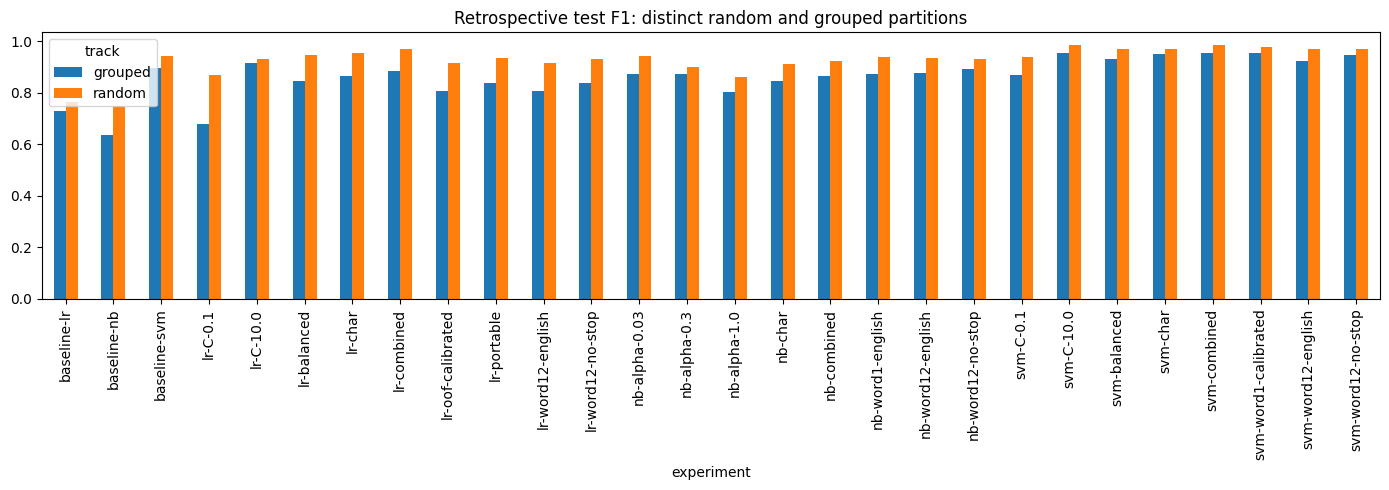

Validation-selected random svm-combined validation F1 0.9682539682539683 test {'records': 511, 'precision': 1.0, 'recall': 0.9692307692307692, 'f1': 0.9843749999999999, 'accuracy': 0.9960861056751468, 'average_precision': 0.9989010989010985, 'roc_auc': 0.9998275267333563, 'false_positive_rate': 0.0, 'false_negative_rate': 0.03076923076923077, 'confusion': {'tn': 446, 'fp': 0, 'fn': 2, 'tp': 63}, 'brier': 0.003277326134850495, 'log_loss': 0.020783832132951364, 'ranking_score': 'probability-like, calibration quality unvalidated'}


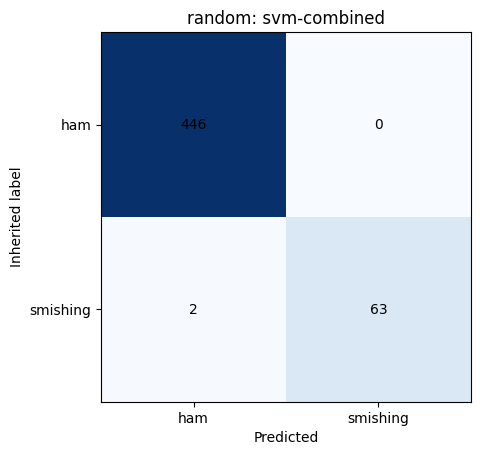

Validation-selected grouped svm-C-10.0 validation F1 0.9655172413793103 test {'records': 498, 'precision': 0.9459459459459459, 'recall': 0.958904109589041, 'f1': 0.9523809523809523, 'accuracy': 0.9859437751004017, 'average_precision': 0.9852930833663742, 'roc_auc': 0.997324738114424, 'false_positive_rate': 0.009411764705882352, 'false_negative_rate': 0.0410958904109589, 'confusion': {'tn': 421, 'fp': 4, 'fn': 3, 'tp': 70}, 'brier': 0.015670706124958904, 'log_loss': 0.06074149424438773, 'ranking_score': 'probability-like, calibration quality unvalidated'}


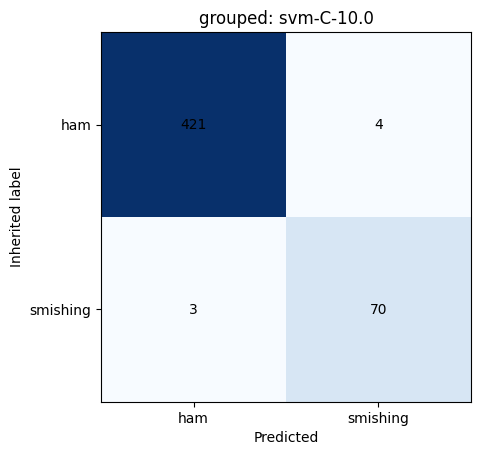

In [16]:
comparison=table(baseline+improved,"test")
comparison.to_csv(RUN/"comparison.csv",index=False)
display(comparison)
comparison[comparison.phase!="diagnostic"].pivot(index="experiment",columns="track",values="f1").plot.bar(figsize=(14,5),title="Retrospective test F1: distinct random and grouped partitions")
plt.tight_layout();plt.show()
for track,key in selected.items():
    r=next(r for r in improved if r["track"]==track and r["id"]==key)
    print("Validation-selected",track,key,"validation F1",r["validation"]["f1"],"test",r["test"])
    c=r["test"]["confusion"];matrix=np.array([[c["tn"],c["fp"]],[c["fn"],c["tp"]]])
    fig,ax=plt.subplots();ax.imshow(matrix,cmap="Blues")
    for (i,j),v in np.ndenumerate(matrix): ax.text(j,i,str(v),ha="center",va="center")
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["ham","smishing"],yticklabels=["ham","smishing"],xlabel="Predicted",ylabel="Inherited label",title=f"{track}: {key}")
    plt.show()

## J. Export and Android compatibility
All fitted pipelines, exact vocabulary/feature ordering and IDF remain private in `pipeline.pkl`. The existing Android contracts support specific word features; Unicode stopword bigrams and char/combined candidates cannot be installed by copying a sklearn pickle. A separately fitted `lr-portable` comparator exports the existing schema-1 word-unigram contract with an OOF sigmoid, `[not_suspicious,suspicious]`, inclusive threshold, and `calibration_evaluated=false`. Python probes verify export to 1e-10. This comparator is exported for JVM verification, not installed as a replacement.

From repository root: `gradlew :app:testDevelopmentUnitTest -PmodelParityDir=<absolute RUN/parity>`. Existing JVM tests also cover fail-closed input and probability wording. The active supplied schema-2 model remains unchanged; its warnings/permissions/report safeguards are unchanged. Empty/OOD numerical values are diagnostic scores, never user-facing probabilities. No physical-device test is claimed.

In [17]:
print(summary["parity"])
print("Private parity directory:",RUN/"parity")
print("Deployment decision:",summary["deployment"])
# JVM verification is external to Colab; the repository handoff records actual local results.

{'model_sha256': 'e2862280681b4a3e79436d3d4709f1516d178ec4b591ed236be5b2600c6f672d', 'cases': 10, 'scope': 'Compatible comparator, not installation or winner validation'}
Private parity directory: runs\bantaytext-20261013\notebook-run-v3\parity
Deployment decision: Retain existing model; independent label/prospective evidence insufficient


## K. Reproducibility and limitations
Run top-to-bottom in a fresh RUN directory. Install the stated dependencies, supply the authorized masked JSON, and retain the original-source/private audit alongside it. Exact local input SHA is saved in configuration.json. Every metric displayed above comes from predictions generated in this execution. The current default corpus was historically exposed; fresh splits cannot undo that. Masking and inherited rule labels can create shortcut bias; source-only and URL-removal diagnostics assess some effects. Near grouping is approximate, no verified chronology exists, source bias and broader-than-financial scope remain, and independent labels/prospective data/calibration quality/device resource testing remain unresolved. Keep parameters and row ledgers private.

References: user-supplied BantayText discussion is a hypothesis, not a published setting validation. [sklearn NB](https://scikit-learn.org/1.6/modules/naive_bayes.html), [TF-IDF](https://scikit-learn.org/1.6/modules/feature_extraction.html#text-feature-extraction), [calibration](https://scikit-learn.org/1.6/modules/calibration.html), [leakage](https://scikit-learn.org/1.6/common_pitfalls.html#data-leakage), and source credits in `docs/source-evidence.md`.

In [18]:
key=selected["grouped"]
chosen=next(r for r in improved if r["track"]=="grouped" and r["id"]==key) if key else None
print({"grouped_validation_selected":key,"validation_metrics":chosen["validation"] if chosen else None,"retrospective_test_metrics":chosen["test"] if chosen else None,"decision":summary["deployment"],"remaining":"Independent labels, unseen prospective evaluation, calibration/deployment review and phone benchmarks"})

{'grouped_validation_selected': 'svm-C-10.0', 'validation_metrics': {'records': 516, 'precision': 0.9491525423728814, 'recall': 0.9824561403508771, 'f1': 0.9655172413793103, 'accuracy': 0.9922480620155039, 'average_precision': 0.984771162025118, 'roc_auc': 0.997897794595421, 'false_positive_rate': 0.006535947712418301, 'false_negative_rate': 0.017543859649122806, 'confusion': {'tn': 456, 'fp': 3, 'fn': 1, 'tp': 56}, 'brier': 0.010219469626084457, 'log_loss': 0.045875641741742246, 'ranking_score': 'probability-like, calibration quality unvalidated'}, 'retrospective_test_metrics': {'records': 498, 'precision': 0.9459459459459459, 'recall': 0.958904109589041, 'f1': 0.9523809523809523, 'accuracy': 0.9859437751004017, 'average_precision': 0.9852930833663742, 'roc_auc': 0.997324738114424, 'false_positive_rate': 0.009411764705882352, 'false_negative_rate': 0.0410958904109589, 'confusion': {'tn': 421, 'fp': 4, 'fn': 3, 'tp': 70}, 'brier': 0.015670706124958904, 'log_loss': 0.06074149424438773, 